# Set Covering Problem — Genetic Algorithm with a random initial population

This notebook solves the Set Covering Problem (SCP) with a **genetic algorithm (GA)** built on an
**element-to-set chromosome encoding** that cannot produce infeasible individuals.
**No constructive heuristic is used:** the initial population consists only of
**random feasible binary solutions**, cleaned once with **redundancy elimination (RE)** and then encoded as chromosomes of set ids.
RE is applied only when a random solution is created (initial population and random immigrants); the GA loop itself has no local search.

### Contents
1. Imports and configuration.
2. OR-Library instance reader.
3. Solution state (`SCPInstance`).
4. Instance loading and best-known solutions (BKS).
5. Element-to-set encoding and the random initial population (random binary solution + feasibility + RE).
6. GA design and pseudocode.
7. GA operators and main loop (tournament, multi-point crossover, mutation, random immigrants, (N + N) survivor selection, stopping by a **time limit** only).
8. Single run (short demonstration): validation, reproducibility, convergence and diversity plots.
9. **Experimental design:** parameter study with a **time limit per run**, several seeds, results table and comparative figures.


## 1. Imports and configuration

`DATA_DIR` is relative to the notebook's working directory; the OR-Library files must be in `SCP-Instances/` next to the notebook.

In [1]:
import re
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:                                    # inside Jupyter
    from IPython.display import display
except ImportError:                     # plain python fallback
    display = print


DATA_DIR = Path("SCP-Instances")
SEED = 42


## 2. OR-Library SCP format

Each instance has the form

```text
m n
c_1 ... c_n
k_1 <k_1 column indices>
...
k_m <k_m column indices>
```

Here `m` is the number of elements (rows) and `n` is the number of available sets (columns). The file uses **1-based** column indices; the implementation converts them to **0-based** indices.

In [2]:
def read_scp_instance(filepath):
    """Read one SCP instance in OR-Library format.

    Format:
        m n
        c_1 ... c_n
        k_1 <k_1 column indices (1-based)>
        ...
        k_m <k_m column indices (1-based)>

    Returns dict containing m, n, costs array, rows list, and cols list.
    """
    filepath = Path(filepath)
    tokens = filepath.read_text().split()
    if len(tokens) < 2:
        raise ValueError(f"{filepath}: file is too short to contain m and n")

    values = [int(x) for x in tokens]
    idx = 0
    m, n = values[idx], values[idx + 1]
    idx += 2

    if m <= 0 or n <= 0:
        raise ValueError(f"{filepath}: invalid dimensions m={m}, n={n}")

    costs = np.asarray(values[idx : idx + n], dtype=float)
    idx += n

    rows = []
    for e in range(m):
        k = values[idx]
        idx += 1
        covering = [c - 1 for c in values[idx : idx + k]]  # Convert to 0-based
        idx += k
        rows.append(covering)

    cols = [[] for _ in range(n)]
    for e, covering in enumerate(rows):
        for j in covering:
            cols[j].append(e)

    return {"m": m, "n": n, "costs": costs, "rows": rows, "cols": cols}

## 3. Solution state

`SCPInstance` stores the instance data (costs, `rows`: element -> covering sets, `cols`: set -> covered elements, as lists and numpy arrays) and an incremental solution state. In this notebook the state is only used to **verify the final solution independently** of the GA (`add_set` for every selected set, then `check_solution`: complete cover and cost equal to the recomputed cost).

| State | Meaning | Update/query |
|---|---|---|
| `chosen[j]` | set `j` is selected | O(1) lookup |
| `cover_count[e]` | number of selected sets covering element `e` | updated only when a set is added/removed |
| `uncovered` + `_pos` | current uncovered elements | O(1) swap-remove/append |
| `gain[j]` | number of currently uncovered elements that set `j` would cover | maintained incrementally |
| `solution_cost` | total cost of selected sets | O(1) update |


In [3]:
class SCPInstance:
    """Maintains incremental solution state for Set Covering Problem.

    State variables maintained in O(1) / O(k):
    - chosen: boolean mask of selected sets
    - cover_count: number of selected sets covering element e
    - gain: number of uncovered elements covered by set j
    - uncovered & _pos: O(1) list for fast sampling and state maintenance
    - solution_cost: total cost of currently chosen sets
    """

    def __init__(self, data, name=None):
        self.name = name
        self.m, self.n = data["m"], data["n"]
        self.costs = np.asarray(data["costs"], dtype=float)
        self.rows = data["rows"] # element -> covering sets (lists)
        self.cols = data["cols"]  # set -> covered elements (lists)
        self.rows_np = [np.asarray(r, dtype=np.int64) for r in self.rows]
        self.cols_np = [np.asarray(c, dtype=np.int64) for c in self.cols]
        self.col_size = np.asarray([len(c) for c in self.cols], dtype=np.int64)
        self.reset()

    # ---------------------------------------------------------------- state
    def reset(self):
        self.chosen = np.zeros(self.n, dtype=bool)
        self.cover_count = np.zeros(self.m, dtype=np.int64)
        self.gain = self.col_size.copy()    # nothing covered yet -> gain = column size
        self.uncovered = list(range(self.m))  # list of uncovered elements
        self._pos = np.arange(self.m, dtype=np.int64) # position of each element inside `uncovered`
        self.solution_cost = 0.0

    def snapshot(self):
        """Return a deep copy snapshot of current state."""
        return {
            "chosen": self.chosen.copy(),
            "cover_count": self.cover_count.copy(),
            "gain": self.gain.copy(),
            "uncovered": self.uncovered.copy(),
            "_pos": self._pos.copy(),
            "solution_cost": float(self.solution_cost),
        }

    def restore(self, state):
        """Restore instance state from a snapshot."""
        self.chosen = state["chosen"].copy()
        self.cover_count = state["cover_count"].copy()
        self.gain = state["gain"].copy()
        self.uncovered = state["uncovered"].copy()
        self._pos = state["_pos"].copy()
        self.solution_cost = float(state["solution_cost"])

    def is_complete_cover(self):
        return len(self.uncovered) == 0

    def solution_sets(self):
        return np.flatnonzero(self.chosen).tolist()
    
    # ------------------------------------------------ O(1) uncovered-list ops
    def _mark_covered(self, e):
        pos = int(self._pos[e])
        last = self.uncovered.pop()
        if last != e:
            self.uncovered[pos] = last
            self._pos[last] = pos
        self.gain[self.rows_np[e]] -= 1

    def _mark_uncovered(self, e):
        self._pos[e] = len(self.uncovered)
        self.uncovered.append(e)
        self.gain[self.rows_np[e]] += 1

    # ------------------------------------------------------------ mutations
    def add_set(self, j):
        j = int(j)
        if self.chosen[j]:
            return 0
        self.chosen[j] = True
        self.solution_cost += self.costs[j]

        els = self.cols_np[j]
        self.cover_count[els] += 1
        newly_covered = els[self.cover_count[els] == 1]
        for e in newly_covered:
            self._mark_covered(int(e))
        return len(newly_covered)

    def remove_set(self, j):
        j = int(j)
        if not self.chosen[j]:
            return 0
        self.chosen[j] = False
        self.solution_cost -= self.costs[j]

        els = self.cols_np[j]
        self.cover_count[els] -= 1
        newly_uncovered = els[self.cover_count[els] == 0]
        for e in newly_uncovered:
            self._mark_uncovered(int(e))
        return len(newly_uncovered)
    
    # -------------------------------------------------------------- queries
    def is_removable(self, j):
        """A set is removable if all its covered elements are covered by >= 2 sets."""
        return bool(np.all(self.cover_count[self.cols_np[int(j)]] > 1))
    
    # -------------------------------------------------------- verification
    def check_solution(self):
        """Verify feasibility and cost correctness."""
        covered = np.zeros(self.m, dtype=bool)
        for j in np.flatnonzero(self.chosen):
            covered[self.cols_np[j]] = True
        if not covered.all():
            raise AssertionError(f"{self.name}: incomplete set cover")
        if not np.isclose(self.solution_cost, self.costs[self.chosen].sum()):
            raise AssertionError(f"{self.name}: cost mismatch")

## 4. Instance loading and best-known solutions

The filename convention maps names such as `scp42.txt` to the label `4.2`, `scp410.txt` to `4.10` and `scpA3.txt` to `A.3`. Duplicate labels are rejected rather than silently overwritten.

The Best Known Solution (BKS) dictionary is kept separate from the algorithm code so that the percentage deviation is easy to audit. It contains the **42** benchmark instances used here (4.2-4.9, 5.1-5.9, 6.1-6.5, A.1-A.5, B.1-B.5, C.1-C.5, D.1-D.5). A check asserts that the table has 42 entries. A file whose label is not in the table (for example 4.1, 4.10 or 5.10) makes the loader raise "Missing BKS values".

In [4]:
FNAME_RE = re.compile(r"scp([A-Za-z]|\d)(\d+)", re.IGNORECASE)

def label_from_filename(path):
    match = FNAME_RE.search(Path(path).name)
    if not match:
        return None
    group, num = match.groups()
    return f"{group.upper()}.{num}"

def sort_key(label):
    cls, num = label.split(".")
    return (cls, int(num))

def load_all_instances(data_dir):
    data_dir = Path(data_dir)
    if not data_dir.exists():
        return {}

    instances = {}
    for path in sorted(data_dir.iterdir()):
        if not path.is_file():
            continue
        label = label_from_filename(path)
        if label is None:
            continue
        if label in instances:
            raise ValueError(f"Duplicate instance label {label!r}: multiple files match it")
        instances[label] = SCPInstance(read_scp_instance(path), name=label)

    return dict(sorted(instances.items(), key=lambda kv: sort_key(kv[0])))

BKS = {
    "4.2": 512, "4.3": 516, "4.4": 494, "4.5": 512,
    "4.6": 560, "4.7": 430, "4.8": 492, "4.9": 641, 
    "5.1": 253, "5.2": 302, "5.3": 226, "5.4": 242, "5.5": 211,
    "5.6": 213, "5.7": 293, "5.8": 288, "5.9": 279, 
    "6.1": 138, "6.2": 146, "6.3": 145, "6.4": 131, "6.5": 161,
    "A.1": 253, "A.2": 252, "A.3": 232, "A.4": 234, "A.5": 236,
    "B.1": 69,  "B.2": 76,  "B.3": 80,  "B.4": 79,  "B.5": 72,
    "C.1": 227, "C.2": 219, "C.3": 243, "C.4": 219, "C.5": 215,
    "D.1": 60, "D.2": 66, "D.3": 72, "D.4": 62, "D.5": 61,
}

assert len(BKS) == 42, f"BKS table should have 42 entries, found {len(BKS)}"

instances = load_all_instances(DATA_DIR)
if not instances:
    print(f"No SCP instances found in {DATA_DIR.resolve()}. Add the Moodle files and rerun this section.")
else:
    missing_bks = sorted(set(instances) - set(BKS), key=sort_key)
    if missing_bks:
        raise ValueError(f"Missing BKS values for: {missing_bks}")
    print(f"Loaded {len(instances)} instance(s): {list(instances)}")
    not_found = sorted(set(BKS) - set(instances), key=sort_key)
    if not_found:
        print(f"WARNING: no file found for {len(not_found)} instance(s) listed in BKS: {not_found}. "
              "Check the data folder / file names (the standard benchmark has 45 instances).")

Loaded 42 instance(s): ['4.2', '4.3', '4.4', '4.5', '4.6', '4.7', '4.8', '4.9', '5.1', '5.2', '5.3', '5.4', '5.5', '5.6', '5.7', '5.8', '5.9', '6.1', '6.2', '6.3', '6.4', '6.5', 'A.1', 'A.2', 'A.3', 'A.4', 'A.5', 'B.1', 'B.2', 'B.3', 'B.4', 'B.5', 'C.1', 'C.2', 'C.3', 'C.4', 'C.5', 'D.1', 'D.2', 'D.3', 'D.4', 'D.5']


## 5. Element-to-set encoding and random initial population

### 5.1 Encoding

A solution is a vector of length **m** (one gene per element). Gene `e` holds the index of **one set that covers element `e`**:

| | |
|---|---|
| chromosome | `x[e] in rows[e]`, i.e. the gene of element `e` can only take values among the sets that contain `e` |
| decoding | the selected sets are the **distinct values** of the chromosome; `cost = sum of their costs` |
| feasibility | every element has an assigned set that covers it, so the decoded solution is **always a cover**. No feasibility check or repair is needed after crossover, and mutation only has to draw a value from `rows[e]` |

*Example (sets numbered from 1 as in the discussion, the code is 0-based):* the binary solution `P1 = (1 0 1 1 0 0)` is encoded as `[1 1 3 3 4]`: elements 1 and 2 are covered by set 1, elements 3 and 4 by set 3, element 5 by set 4.

### 5.2 From a binary solution to a chromosome

A binary solution can cover an element with several of its selected sets. The gene of each element is chosen with this rule:

1. elements are processed from the **most constrained** (fewest selected sets covering them) to the least constrained. Elements with a single selected set have no choice, so they fix the first "used" sets;
2. if some selected set covering the element is **already used by another gene**, the choice is made among those;
3. otherwise the choice is made among all selected sets covering the element;
4. within that group the set with the **lowest cost per element covered** (`cost / number of elements the set covers`) is written in the cell; ties go to the lowest index.

Because genes only use selected sets, the decoded solution is a **subset** of the binary solution: sets that nobody needs (redundant sets, very common in random solutions) disappear, so the decoded cost is never higher than the cost of the binary string.

### 5.3 Random feasible binary solutions with redundancy elimination (initial population)

Every individual of the initial population is built as follows:

1. draw a density `p` uniformly in [`DENSITY_MIN`, `DENSITY_MAX`] (a different `p` for each individual gives individuals of different size and cost);
2. a **binary string** of length `n` is drawn, each set being selected with probability `p`;
3. **feasibility:** every element left uncovered is covered by one set drawn at random among the sets that contain it (uncovered elements are processed in random order and skipped if an earlier repair already covered them);
4. **redundancy elimination (RE):** the selected sets are examined **once, from the most to the least expensive**, and a set is removed if every element it covers is covered by at least one other selected set (checked at removal time, so removing one set can make another one non-removable). The result is still a cover and has **no redundant set**. It is controlled by `USE_RE_INIT` (`True` = baseline);
5. the binary string is **encoded** with the rule of 5.2.

Besides the random draws, no cost information is used, so the individuals are still random covers, only without the useless sets. RE is **not** applied inside the GA loop. Repeated chromosomes are avoided.


In [5]:
# ----------------------------------------------------------------------------
# Element -> set encoding:  x[e] = a set that covers element e   (length m, 0-based set ids)
# ----------------------------------------------------------------------------
def decode_chromosome(inst, chromosome):
    """Chromosome -> (binary solution, cost). The selected sets are the distinct genes."""
    chosen = np.zeros(inst.n, dtype=bool)
    chosen[np.asarray(chromosome, dtype=np.int64)] = True
    return chosen, float(inst.costs[chosen].sum())


def is_valid_chromosome(inst, chromosome):
    """Every gene must be a set that really contains its element."""
    g = np.asarray(chromosome)
    if g.shape != (inst.m,):
        return False
    return all(bool((inst.rows_np[e] == g[e]).any()) for e in range(inst.m))


def covers_all_elements(inst, chosen):
    covered = np.zeros(inst.m, dtype=bool)
    for j in np.flatnonzero(chosen):
        covered[inst.cols_np[j]] = True
    return bool(covered.all())


def count_redundant_sets(inst, chosen):
    """Selected sets whose elements are all covered by at least two selected sets (individually removable)."""
    sel = np.flatnonzero(chosen)
    cc = np.zeros(inst.m, dtype=np.int64)
    for j in sel:
        cc[inst.cols_np[j]] += 1
    return int(sum(bool(np.all(cc[inst.cols_np[j]] > 1)) for j in sel))


def encode_solution(inst, chosen):
    """Binary solution (feasible cover) -> chromosome.

    Rule for the gene of each element (see 8.2): most constrained elements first; among the selected
    sets that cover the element prefer one that is already used by another gene; among those take the set
    with the lowest cost per element covered (cost / |set|); ties -> lowest index."""
    chosen = np.asarray(chosen, dtype=bool)
    covering = [r[chosen[r]] for r in inst.rows_np]          # selected sets that cover each element
    if any(c.size == 0 for c in covering):
        raise ValueError(f"{inst.name}: the binary solution is not a cover")

    order = sorted(range(inst.m), key=lambda e: (covering[e].size, e))
    used = np.zeros(inst.n, dtype=bool)
    chrom = np.empty(inst.m, dtype=np.int64)
    for e in order:
        cand = covering[e]
        pool = cand[used[cand]]
        if pool.size == 0:
            pool = cand
        ratio = inst.costs[pool] / inst.col_size[pool]            # cost per element covered
        j = int(pool[np.lexsort((pool, ratio))[0]])               # lowest ratio, then lowest index
        chrom[e] = j
        used[j] = True
    return chrom

In [6]:
# ----------------------------------------------------------------------------
# Random feasible binary solutions (+ redundancy elimination) -> chromosomes
# ----------------------------------------------------------------------------
POP_SIZE = 100                  # individuals in the initial population (N)
DENSITY_MIN, DENSITY_MAX = 0.0, 0.05   # each set is selected with probability p ~ U(DENSITY_MIN, DENSITY_MAX)
USE_RE_INIT = True              # apply redundancy elimination to every random solution (initial population + immigrants)
MAX_DUP_TRIES = 20              # attempts to avoid repeating an individual
GA_SEED = SEED


def random_feasible_binary(inst, rng, density_min=DENSITY_MIN, density_max=DENSITY_MAX):
    """Random binary string (selected sets) made feasible: uncovered elements get a random covering set."""
    p = rng.uniform(density_min, density_max)
    chosen = rng.random(inst.n) < p                                 # random binary string
    covered = np.zeros(inst.m, dtype=bool)
    for j in np.flatnonzero(chosen):
        covered[inst.cols_np[j]] = True
    for e in rng.permutation(np.flatnonzero(~covered)):            # feasibility: cover the rest at random
        if not covered[e]:
            j = int(rng.choice(inst.rows_np[e]))
            chosen[j] = True
            covered[inst.cols_np[j]] = True
    return chosen


def redundancy_elimination(inst, chosen):
    """RE on a binary cover: examine the selected sets once, from the most to the least expensive (ties: lowest
    index), and remove a set if all its elements are covered by another selected set (checked at removal time).
    Returns a new binary cover without redundant sets that costs no more than the input."""
    chosen = np.asarray(chosen, dtype=bool).copy()
    sel = np.flatnonzero(chosen)
    cover = np.zeros(inst.m, dtype=np.int64)
    for j in sel:
        cover[inst.cols_np[j]] += 1
    for j in sel[np.argsort(-inst.costs[sel], kind="stable")]:
        els = inst.cols_np[j]
        if (cover[els] > 1).all():
            cover[els] -= 1
            chosen[j] = False
    return chosen


def random_solution(inst, rng, use_re=USE_RE_INIT):
    """One random feasible binary solution; returns (binary after RE if use_re, binary before RE)."""
    b = random_feasible_binary(inst, rng)
    return (redundancy_elimination(inst, b) if use_re else b), b


def random_individuals(inst, count, rng, use_re=USE_RE_INIT):
    """`count` new random feasible solutions, encoded. Returns (chromosomes (count, m), binaries (count, n))."""
    binaries = [random_solution(inst, rng, use_re)[0] for _ in range(count)]
    return np.vstack([encode_solution(inst, b) for b in binaries]), np.vstack(binaries)


def build_initial_population(inst, pop_size=POP_SIZE, seed=GA_SEED, max_dup_tries=MAX_DUP_TRIES, use_re=USE_RE_INIT):
    """Initial GA population: random feasible binary solutions (+ RE), encoded (element-to-set encoding).

    Returns {"chromosomes": int array (pop_size, m), "binaries": bool array (pop_size, n),
             "info": DataFrame with one row per individual}.
    `Random_Cost` is the cost of the random feasible string, `Binary_Cost` the cost after RE (same if use_re=False)
    and `Decoded_Cost` the cost of the decoded chromosome (<= Binary_Cost)."""
    rng = np.random.default_rng(seed)
    chromosomes, binaries, records, seen = [], [], [], set()
    for _ in range(pop_size):
        for _ in range(max_dup_tries):
            t0 = time.perf_counter()
            b, b_raw = random_solution(inst, rng, use_re)
            chrom = encode_solution(inst, b)
            elapsed = time.perf_counter() - t0
            if chrom.tobytes() not in seen:
                break
        chosen_dec, dec_cost = decode_chromosome(inst, chrom)
        records.append({"Random_Cost": float(inst.costs[b_raw].sum()), "Random_Sets": int(b_raw.sum()),
                        "Binary_Cost": float(inst.costs[b].sum()), "Binary_Sets": int(b.sum()),
                        "Decoded_Cost": dec_cost, "Decoded_Sets": int(chosen_dec.sum()),
                        "Redundant_Sets": count_redundant_sets(inst, chosen_dec),
                        "Duplicate": chrom.tobytes() in seen, "Time_s": elapsed})
        seen.add(chrom.tobytes())
        chromosomes.append(chrom)
        binaries.append(b)
    return {"chromosomes": np.vstack(chromosomes), "binaries": np.vstack(binaries), "info": pd.DataFrame(records)}


def validate_population(inst, pop, use_re=USE_RE_INIT):
    """Every individual: binary string is a cover (without redundant sets if RE was used), genes in rows[e],
    decoded solution is a cover and a subset of the binary string, stored cost is right, and decoding never
    increases the cost. RE never increases the cost either."""
    info = pop["info"]
    assert pop["chromosomes"].shape == (len(info), inst.m) and pop["binaries"].shape == (len(info), inst.n)
    for chrom, b, row in zip(pop["chromosomes"], pop["binaries"], info.itertuples()):
        assert covers_all_elements(inst, b), f"{inst.name}: binary string is not a cover"
        if use_re:
            assert count_redundant_sets(inst, b) == 0, f"{inst.name}: RE left a redundant set"
        assert row.Binary_Cost <= row.Random_Cost + 1e-6, f"{inst.name}: RE increased the cost"
        assert is_valid_chromosome(inst, chrom), f"{inst.name}: gene outside rows[e]"
        chosen, cost = decode_chromosome(inst, chrom)
        assert covers_all_elements(inst, chosen), f"{inst.name}: decoded solution is not a cover"
        assert not (chosen & ~b).any(), f"{inst.name}: decoded solution uses a set that the binary string did not select"
        assert abs(cost - row.Decoded_Cost) < 1e-6, f"{inst.name}: stored cost differs"
        assert cost <= row.Binary_Cost + 1e-6, f"{inst.name}: decoding increased the cost"


### 5.4 Build and validate the initial population for one instance

Set `GA_LABEL` to the instance you want to work on. `POP_SIZE`, `DENSITY_MIN`, `DENSITY_MAX` and `USE_RE_INIT` are defined in the cell above. The validation checks, for every individual, that the binary string is a cover without redundant sets, that all genes are admissible, that the decoded solution is a cover contained in the binary solution, and that the cost is consistent.


In [7]:
GA_LABEL = "4.2"                       # instance used by the GA

if GA_LABEL in instances:
    inst = instances[GA_LABEL]
    population = build_initial_population(inst)
    validate_population(inst, population)
    chromosomes, pop_info = population["chromosomes"], population["info"]
    print(f"Instance {GA_LABEL}: m = {inst.m} elements, n = {inst.n} sets, BKS = {BKS[GA_LABEL]}")
    print(f"OK: {len(pop_info)} chromosomes {chromosomes.shape} (rows = individuals, columns = elements, "
          f"value = covering set) are admissible and decode to feasible covers.")
else:
    population = chromosomes = pop_info = None
    print(f"Instance {GA_LABEL!r} not found. Available: {list(instances)}")


Instance 4.2: m = 200 elements, n = 1000 sets, BKS = 512
OK: 100 chromosomes (100, 200) (rows = individuals, columns = elements, value = covering set) are admissible and decode to feasible covers.


In [8]:
# ---- The initial population ---------------------------------------------------------------------------------
if population is not None:
    bks = float(BKS[GA_LABEL])
    pop_info["Pct_Dev"] = 100 * (pop_info["Decoded_Cost"] - bks) / bks     # decoded cost vs BKS
    display(pop_info.round(3).head(10))
    print("Initial population:")
    display(pop_info[["Random_Cost", "Binary_Cost", "Decoded_Cost", "Pct_Dev", "Random_Sets", "Binary_Sets", "Decoded_Sets", "Redundant_Sets"]].describe().round(1))
    print(f"Distinct chromosomes: {int((~pop_info['Duplicate']).sum())} of {len(pop_info)}")
    print(f"Cost saved by RE (random feasible string -> after RE): "
          f"{100 * (1 - pop_info['Binary_Cost'].sum() / pop_info['Random_Cost'].sum()):.1f} %   |   "
          f"by decoding (unused sets drop out): {100 * (1 - pop_info['Decoded_Cost'].sum() / pop_info['Binary_Cost'].sum()):.1f} %")
    b0 = population["binaries"][0]
    print(f"Individual 0: after RE the binary string selects {int(b0.sum())} sets (random string had {int(pop_info['Random_Sets'][0])}), "
          f"first selected set ids = {np.flatnonzero(b0)[:10].tolist()} ...")
    print(f"              chromosome (first 15 genes)       = {chromosomes[0][:15].tolist()}")
    print(f"              best individual of the population = {pop_info['Decoded_Cost'].min():.0f} "
          f"({pop_info['Pct_Dev'].min():+.1f} % vs BKS)")


,Random_Cost,Random_Sets,Binary_Cost,Binary_Sets,Decoded_Cost,Decoded_Sets,Redundant_Sets,Duplicate,Time_s,Pct_Dev
0,5140.0,91,3954.0,70,3954.0,70,0,False,0.006,672.266
1,4301.0,86,3281.0,66,3281.0,66,0,False,0.002,540.820
2,4769.0,90,3504.0,69,3504.0,69,0,False,0.002,584.375
3,4569.0,88,3501.0,67,3501.0,67,0,False,0.006,583.789
4,4478.0,93,2865.0,66,2865.0,66,0,False,0.003,459.570
5,4922.0,100,3145.0,72,3145.0,72,0,False,0.003,514.258
6,4809.0,92,3559.0,69,3559.0,69,0,False,0.005,595.117
7,4106.0,82,2759.0,61,2759.0,61,0,False,0.004,438.867
8,4080.0,81,3298.0,67,3298.0,67,0,False,0.004,544.141
9,4664.0,94,3429.0,69,3429.0,69,0,False,0.006,569.727


Initial population:


,Random_Cost,Binary_Cost,Decoded_Cost,Pct_Dev,Random_Sets,Binary_Sets,Decoded_Sets,Redundant_Sets
count,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
mean,4388.0,3220.3,3220.3,529.0,88.3,66.9,66.9,0.0
std,368.4,298.0,298.0,58.2,5.7,3.3,3.3,0.0
min,3607.0,2400.0,2400.0,368.8,78.0,57.0,57.0,0.0
25%,4141.5,2996.5,2996.5,485.3,84.0,65.0,65.0,0.0
50%,4325.5,3236.5,3236.5,532.1,88.0,67.0,67.0,0.0
75%,4653.5,3454.5,3454.5,574.7,92.0,69.0,69.0,0.0
max,5457.0,4007.0,4007.0,682.6,101.0,74.0,74.0,0.0


Distinct chromosomes: 100 of 100
Cost saved by RE (random feasible string -> after RE): 26.6 %   |   by decoding (unused sets drop out): 0.0 %
Individual 0: after RE the binary string selects 70 sets (random string had 91), first selected set ids = [66, 67, 83, 90, 93, 122, 134, 162, 164, 180] ...
              chromosome (first 15 genes)       = [319, 756, 219, 164, 162, 766, 219, 67, 602, 870, 483, 90, 162, 576, 603]
              best individual of the population = 2400 (+368.8 % vs BKS)


## 6. GA design and pseudocode

**Family: genetic algorithm.** For the SCP there is a representation in which crossover is meaningful and *never leaves the feasible space* (the element-to-set encoding of section 5), so no repair or penalty is needed. This is a **pure GA**: no constructive heuristic; redundancy elimination is used only to clean the random solutions when they are created, not inside the GA loop.

| Design question | Decision |
|---|---|
| **1. Representation** | One individual is a vector of length `m`; gene `e` is the id of one set that contains element `e`. The SCP solution it represents is the **set of distinct gene values** (the selected sets). |
| **2. Feasibility** | An infeasible individual **cannot occur**: random binary strings are made feasible when they are created (uncovered elements get a random covering set) and cleaned with RE, crossover only moves genes between chromosomes at the same position, and mutation draws a gene from `rows[e]`. No rejection, repair or penalty in the GA loop. Redundant sets can appear (feasible but expensive); they are simply paid for in the cost. |
| **3. Evaluation** | `cost(x) = sum of the costs of the distinct sets in x`. Lower is better. |
| **4. Initial population** | `N` **random feasible binary solutions** (random density, random repair of the uncovered elements, **RE once** to remove the redundant sets), encoded with the rule of 5.2. No cost-based construction. |
| **5. New solutions** | Repeat until `N` offspring exist: tournament selection of two different parents, multi-point crossover (`MIN_PIECES`..`MAX_PIECES` pieces, alternate pieces swapped) giving two offspring. **Mutation:** half of the offspring (`MUTATION_PROB = 0.5`) get every gene re-drawn with probability `MUTATION_RATE` among the other sets covering its element. **Random immigrants:** every `IMMIGRANT_EVERY = 5` generations, `N_IMMIGRANTS` new random feasible solutions (generated, cleaned with RE and encoded exactly like the initial population) are added to the pool. |
| **6. Population update** | Parents + offspring (+ immigrants) are pooled and the **worst are deleted until `N` remain** (elitist: the best is never lost). With `UNIQUE_SURVIVORS = True` two individuals that decode to the same set of sets count as one, so the survivors are the best `N` **distinct** solutions. |
| **7. Diversity** | Random initial population, crossover of different parents, mutation, random immigrants and `UNIQUE_SURVIVORS`. Premature convergence is visible as `std` -> 0 and `distinct_solutions` -> 1; both are recorded every generation. |
| **8. Stopping** | **Time limit only:** the run stops when `TIME_LIMIT_S` seconds (5 minutes) of the generation loop have elapsed (checked after every generation). There is no limit on the number of generations and no stagnation rule: configurations with a different cost per generation (population size, number of immigrants) get exactly the same computational budget, and the number of generations they manage to complete is recorded as a result. |

### Pseudocode of one complete run

```text
 1  P <- N random feasible binary solutions, each cleaned with RE, encoded as chromosomes;  evaluate: cost = cost of the distinct sets
 2  for g = 1, 2, ...  until TIME_LIMIT_S seconds have elapsed:
 3      O <- empty
 4      while |O| < N:
 5          p1 <- tournament(P);  p2 <- tournament(P), p2 != p1
 6          o1, o2 <- multi-point crossover(p1, p2);   O <- O + {o1, o2}
 7      mutate half of the offspring (each gene re-drawn with prob. MUTATION_RATE)
 8      if g is a multiple of IMMIGRANT_EVERY: O <- O + N_IMMIGRANTS new random feasible solutions (RE + encoded)
 9      evaluate O;   P <- P + O
10      while |P| > N: delete the worst solution of P            (duplicates of a decoded solution count once if UNIQUE_SURVIVORS)
11      record best, mean, std, elapsed time (and distinct chromosomes / decoded solutions);  stop if the time limit is reached
12  return the cheapest chromosome of P -> decode -> selected sets and their cost
```


## 7. GA operators and main loop

The baseline parameters are in the first cell so they can be tuned later.

**What to expect.** The initial individuals are random covers cleaned with RE, so they are far cheaper than raw random covers but still several times the BKS. Crossover of two parents has a good chance of producing something cheaper than the worse parent, so the best cost and the mean of the population should decrease over the generations. Inside the loop nothing removes sets except the decoding of the chromosome (a set that no gene uses disappears), so the GA will not reach the BKS; the interesting quantities are how fast the population improves, how much diversity is kept (`std`, `distinct_solutions`) and how much the result changes with the seed. Compare with `USE_RE_INIT = False` to see the effect of RE.


In [9]:
# ----------------------------------------------------------------------------
# Baseline GA parameters (to be tuned)
# ----------------------------------------------------------------------------
TIME_LIMIT_S = 300              # the ONLY stopping criterion: wall-clock time of one run in seconds (5 minutes)
DEMO_TIME_S = 30                # shorter budget, used only for the quick demonstration run and checks of section 8
TOURNAMENT_K = 2                # tournament size: the better of 2 random individuals
MIN_PIECES, MAX_PIECES = 2, 3   # multi-point crossover: pieces ~ uniform integer in [2, 3] (1-2 cut points)
MUTATION_PROB = 0.5             # fraction of the offspring that is mutated ("mutate half of the offspring")
MUTATION_RATE = 0.01            # probability that a gene of a mutated offspring is re-drawn
IMMIGRANT_EVERY = 5             # every 5 generations new random solutions are added to the pool (None = off)
N_IMMIGRANTS = 10               # how many random feasible solutions are added each time
UNIQUE_SURVIVORS = True         # True: at most one survivor per decoded solution; False: plain "delete the worst"


# ----------------------------------------------------------------------------
# Operators
# ----------------------------------------------------------------------------
def tournament_select(costs, rng, k=TOURNAMENT_K, exclude=None):
    """Pick k distinct random individuals (never `exclude`) and return the index of the cheapest."""
    pool = np.arange(len(costs))
    if exclude is not None:
        pool = np.delete(pool, exclude)
    cand = rng.choice(pool, size=k, replace=False)
    return int(cand[np.argmin(costs[cand])])


def crossover_multipoint(p1, p2, rng, min_pieces=MIN_PIECES, max_pieces=MAX_PIECES):
    """Multi-point crossover. Draw K in [min_pieces, max_pieces] (K >= 2), cut the m genes into K pieces at
    random positions and swap alternate pieces: offspring 1 = pieces 1,3,.. of p1 and 2,4,.. of p2; offspring 2
    is the opposite. Every gene stays in its own position, so both offspring are valid chromosomes."""
    m = len(p1)
    k = min(max(2, int(rng.integers(min_pieces, max_pieces + 1))), m)   # number of pieces (>= 1 cut)
    cuts = np.sort(rng.choice(np.arange(1, m), size=k - 1, replace=False))
    marker = np.zeros(m, dtype=np.int64)
    marker[cuts] = 1
    from_p2 = (np.cumsum(marker) % 2) == 1
    return np.where(from_p2, p2, p1), np.where(from_p2, p1, p2)


def mutate(inst, chrom, rng, rate=MUTATION_RATE):
    """Each gene is re-drawn with probability `rate` among the OTHER sets covering its element (stays valid)."""
    c = chrom.copy()
    for e in np.flatnonzero(rng.random(inst.m) < rate):
        options = inst.rows_np[e][inst.rows_np[e] != c[e]]
        if options.size:
            c[e] = options[rng.integers(options.size)]
    return c


def select_survivors(pool, pool_costs, n, unique=UNIQUE_SURVIVORS):
    """Indices (into the pool) of the n cheapest individuals ("delete the worst until n remain").
    On equal cost an older individual wins (stable sort). With unique=True only one individual per decoded
    solution (set of selected sets) is allowed; a gap, if any, is filled with the cheapest duplicates."""
    order = np.argsort(pool_costs, kind="stable")
    if not unique:
        return order[:n]
    seen, keep = set(), []
    for k in order:
        key = np.unique(pool[k]).tobytes()
        if key not in seen:
            seen.add(key)
            keep.append(int(k))
            if len(keep) == n:
                return np.array(keep)
    kept = set(keep)
    return np.array(keep + [int(k) for k in order if int(k) not in kept][: n - len(keep)])


In [10]:
# ----------------------------------------------------------------------------
# Main loop
# ----------------------------------------------------------------------------
def run_ga(inst, initial_population, time_limit_s=TIME_LIMIT_S,
           tournament_k=TOURNAMENT_K, min_pieces=MIN_PIECES, max_pieces=MAX_PIECES,
           mutation_prob=MUTATION_PROB, mutation_rate=MUTATION_RATE, immigrant_every=IMMIGRANT_EVERY,
           n_immigrants=N_IMMIGRANTS, unique_survivors=UNIQUE_SURVIVORS,
           seed=GA_SEED, verbose=True, track_diversity=True):
    """Pure genetic algorithm, (N + N) survivor selection. See section 6 for the pseudocode.
    The only stopping criterion is the time limit: the loop stops after the first generation that ends once
    `time_limit_s` seconds have passed (the time of the generation loop only, the initial population is built before).
    track_diversity=False skips the (slower) distinct-chromosome counts, used in the long experiments."""
    rng = np.random.default_rng(seed)
    evaluate = lambda chrom: decode_chromosome(inst, chrom)[1]            # fitness = cost of the decoded solution

    pop = initial_population["chromosomes"].copy()
    costs = np.array([evaluate(c) for c in pop])
    N = len(pop)
    keep = select_survivors(pop, costs, N, unique_survivors)              # sorted by cost; pop[0] is the best
    pop, costs = pop[keep], costs[keep]
    t0 = time.perf_counter()

    def snapshot(g, child_costs=None, kept=0, imm_kept=0):
        cc = costs if child_costs is None else child_costs
        return {"generation": g, "elapsed": time.perf_counter() - t0,
                "best": costs[0], "mean": costs.mean(), "worst": costs[-1], "std": costs.std(),
                "child_best": cc.min(), "child_mean": cc.mean(),               # quality of the new offspring only
                "offspring_kept": kept, "immigrants_kept": imm_kept,
                "distinct": len({c.tobytes() for c in pop}) if track_diversity else np.nan,
                "distinct_solutions": len({np.unique(c).tobytes() for c in pop}) if track_diversity else np.nan}

    history = [snapshot(0)]
    last_improvement, last_improvement_time = 0, 0.0
    if verbose:
        print(f"GA on {inst.name}: N = {N}, mutation: {mutation_prob:.0%} of the offspring x {mutation_rate}/gene, "
              f"immigrants: {n_immigrants} every {immigrant_every} gen., unique survivors = {unique_survivors}, "
              f"time limit {time_limit_s} s. Initial best = {costs[0]:.0f}")

    g = 0
    while True:
        g += 1
        # ---- N offspring: tournament + crossover (2 offspring each time) --------------------------------
        children = []
        while len(children) < N:
            i = tournament_select(costs, rng, tournament_k)
            j = tournament_select(costs, rng, tournament_k, exclude=i)    # parent 2 is a different individual
            children += list(crossover_multipoint(pop[i], pop[j], rng, min_pieces, max_pieces))
        children = children[:N]
        # ---- mutate a fraction of the offspring -------------------------------------------------------------
        children = [mutate(inst, c, rng, mutation_rate) if rng.random() < mutation_prob else c for c in children]
        n_children = len(children)
        # ---- random immigrants: new random feasible solutions (binary -> RE -> encoded) every `immigrant_every` generations
        if immigrant_every is not None and g % immigrant_every == 0:
            children += list(random_individuals(inst, n_immigrants, rng)[0])
        child_costs = np.array([evaluate(c) for c in children])

        # ---- join parents + offspring, delete the worst until N remain ---------------------------------------
        pool = np.vstack([pop, np.array(children)])
        pool_costs = np.concatenate([costs, child_costs])
        keep = select_survivors(pool, pool_costs, N, unique_survivors)
        best_before = costs[0]
        pop, costs = pool[keep], pool_costs[keep]
        assert costs[0] <= best_before + 1e-9                             # elitism: the best is never lost
        history.append(snapshot(g, child_costs, int((keep >= N).sum()), int((keep >= N + n_children).sum())))

        if costs[0] < best_before - 1e-9:
            last_improvement, last_improvement_time = g, history[-1]["elapsed"]
        if verbose and g % 50 == 0:
            h = history[-1]
            print(f"  gen {g:4d} | {h['elapsed']:6.1f}s | best {h['best']:.0f} | mean {h['mean']:.1f} | std {h['std']:.2f} | offspring mean {h['child_mean']:.1f} "
                  f"| offspring kept {h['offspring_kept']} | distinct solutions {h['distinct_solutions']}")
        if history[-1]["elapsed"] >= time_limit_s:                         # the only stopping criterion
            break

    elapsed = time.perf_counter() - t0
    if verbose:
        print(f"Finished: time limit reached after {g} generations in {elapsed:.2f}s | final best = {costs[0]:.0f}")
    return {"best_chromosome": pop[0].copy(), "best_cost": float(costs[0]), "history": pd.DataFrame(history),
            "final_population": pop, "final_costs": costs, "time_s": elapsed, "generations": g,
            "last_improvement": last_improvement, "last_improvement_time": last_improvement_time}


## 8. Single run: validation and convergence

The GA runs on the instance chosen in section 5 (`GA_LABEL`), starting from the population built there. Afterwards the best chromosome is decoded, checked to be a cover, and its cost is verified independently with the incremental `SCPInstance` state. This is only a **short demonstration** (`DEMO_TIME_S` seconds instead of the 5 minutes of the experiments). The random seed controls the whole run, but the time limit does not stop it at an exact generation, so two runs with the same seed give the same history up to the generation both reached (checked below).

In [11]:
if population is not None:
    ga_results = run_ga(inst, population, time_limit_s=DEMO_TIME_S)
    hist = ga_results["history"]

    # ---- verify the best solution found ---------------------------------------------------------------
    best_chrom = ga_results["best_chromosome"]
    best_chosen, best_cost = decode_chromosome(inst, best_chrom)
    assert is_valid_chromosome(inst, best_chrom) and covers_all_elements(inst, best_chosen)
    inst.reset()                                    # independent check with the incremental state
    for j in np.flatnonzero(best_chosen):
        inst.add_set(j)
    inst.check_solution()
    assert abs(inst.solution_cost - ga_results["best_cost"]) < 1e-6

    bks = float(BKS[GA_LABEL])
    first_best, last_best = hist["best"].iloc[0], hist["best"].iloc[-1]
    last_improvement = ga_results["last_improvement"]
    print(f"\nBest solution: {int(best_chosen.sum())} sets, cost {best_cost:.0f}  "
          f"({100 * (best_cost - bks) / bks:+.2f} % vs BKS {bks:.0f}),  redundant sets: {count_redundant_sets(inst, best_chosen)}")
    print(f"Initial best {first_best:.0f} -> final best {last_best:.0f}; last improvement at generation {last_improvement}")
    print(f"Offspring: mean cost {hist['child_mean'].iloc[1:].mean():.1f}, best offspring {hist['child_best'].iloc[1:].min():.0f}; "
          f"survivors that were offspring: {hist['offspring_kept'].iloc[1:].mean():.1f} per generation on average")
    print(f"Final population: {int(hist['distinct_solutions'].iloc[-1])} distinct decoded solutions, std of costs {hist['std'].iloc[-1]:.2f}")


GA on 4.2: N = 100, mutation: 50% of the offspring x 0.01/gene, immigrants: 10 every 5 gen., unique survivors = True, time limit 30 s. Initial best = 2400
  gen   50 |    0.5s | best 2024 | mean 2089.8 | std 18.92 | offspring mean 2237.1 | offspring kept 17 | distinct solutions 100
  gen  100 |    0.9s | best 1855 | mean 1872.4 | std 5.04 | offspring mean 2025.7 | offspring kept 8 | distinct solutions 100
  gen  150 |    1.4s | best 1706 | mean 1717.3 | std 5.39 | offspring mean 1885.1 | offspring kept 16 | distinct solutions 100
  gen  200 |    1.8s | best 1660 | mean 1692.5 | std 12.26 | offspring mean 1879.6 | offspring kept 15 | distinct solutions 100
  gen  250 |    2.2s | best 1658 | mean 1661.2 | std 1.08 | offspring mean 1839.3 | offspring kept 0 | distinct solutions 100
  gen  300 |    2.6s | best 1646 | mean 1655.6 | std 1.37 | offspring mean 1853.1 | offspring kept 1 | distinct solutions 100
  gen  350 |    3.0s | best 1615 | mean 1639.7 | std 4.85 | offspring mean 1810.4 | 

In [12]:
# ---- same seed -> same run (reproducibility check) --------------------------------------------------------------
# With a time limit two runs stop at different generations, so the histories are compared up to the last common generation.
if population is not None:
    r1 = run_ga(inst, population, time_limit_s=5, seed=123, verbose=False)
    r2 = run_ga(inst, population, time_limit_s=5, seed=123, verbose=False)
    r3 = run_ga(inst, population, time_limit_s=5, seed=124, verbose=False)
    n_common = min(len(r1["history"]), len(r2["history"]), len(r3["history"]))
    nt = lambda r: r["history"].drop(columns="elapsed").iloc[:n_common]     # wall-clock time is the only thing that differs
    assert nt(r1).equals(nt(r2))
    print(f"Same seed  -> identical history in the first {n_common} generations: OK")
    print(f"Other seed -> history differs: {not nt(r1).equals(nt(r3))}")


Same seed  -> identical history in the first 646 generations: OK
Other seed -> history differs: True


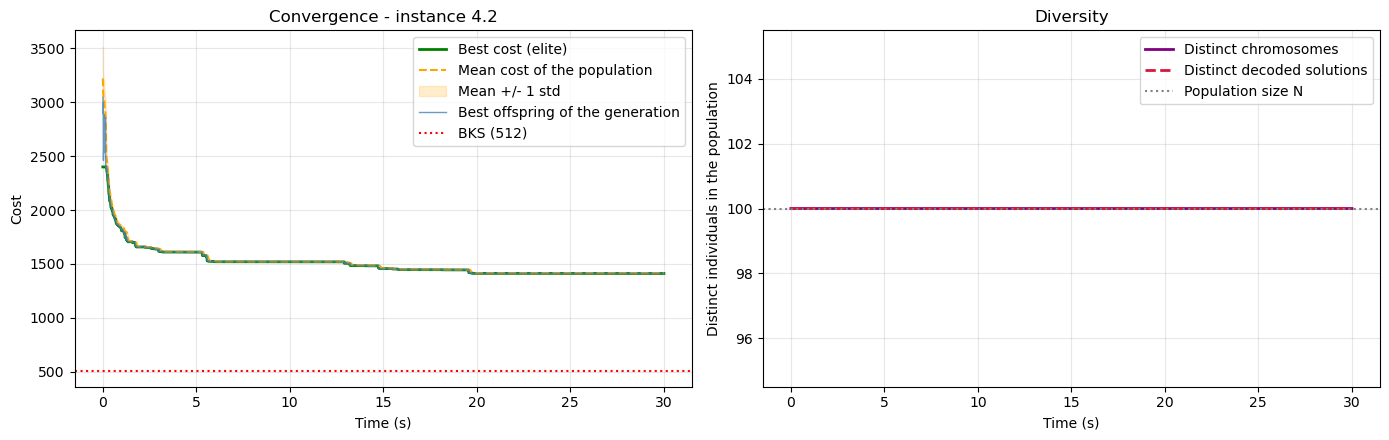

In [13]:
# ---- convergence and diversity plots -----------------------------------------------------------------------
if population is not None:
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
    g_ = hist["elapsed"]

    ax[0].plot(g_, hist["best"], color="green", lw=2, label="Best cost (elite)")
    ax[0].plot(g_, hist["mean"], color="orange", ls="--", label="Mean cost of the population")
    ax[0].fill_between(g_, hist["mean"] - hist["std"], hist["mean"] + hist["std"], color="orange", alpha=0.2, label="Mean +/- 1 std")
    ax[0].plot(g_.iloc[1:], hist["child_best"].iloc[1:], color="steelblue", lw=1, alpha=0.8, label="Best offspring of the generation")
    ax[0].axhline(BKS[GA_LABEL], color="red", ls=":", label=f"BKS ({BKS[GA_LABEL]})")
    ax[0].set(title=f"Convergence - instance {GA_LABEL}", xlabel="Time (s)", ylabel="Cost")
    ax[0].legend(); ax[0].grid(alpha=0.3)

    ax[1].plot(g_, hist["distinct"], color="purple", lw=2, label="Distinct chromosomes")
    ax[1].plot(g_, hist["distinct_solutions"], color="crimson", lw=2, ls="--", label="Distinct decoded solutions")
    ax[1].axhline(len(ga_results["final_population"]), color="grey", ls=":", label="Population size N")
    ax[1].set(title="Diversity", xlabel="Time (s)", ylabel="Distinct individuals in the population")
    ax[1].legend(); ax[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


## 9. Experimental design

**Goal:** see how the three parameters that most affect the GA change its behaviour, under the **same computational budget**: a **wall-clock limit per run** (`TIME_LIMIT_S`, 5 minutes), which is the **only stopping criterion**. A generation costs very different amounts of time with a population of 50 or 200 individuals, or with 10 or 30 immigrants, so a fixed number of generations would not be an equal budget.

| Factor | Meaning | Levels | Baseline |
|---|---|---|---|
| `pop_size` | population size `N` | 50, 100, 200 | 100 |
| `mutation_rate` | probability that a gene of a mutated offspring is re-drawn | 0.01, 0.05, 0.1 | 0.01 |
| `n_immigrants` | random solutions added every `IMMIGRANT_EVERY = 5` generations | 10, 25, 30 | 10 |

All other parameters stay fixed: the fraction of mutated offspring `MUTATION_PROB = 0.5`, tournament size, crossover pieces, `IMMIGRANT_EVERY` and `UNIQUE_SURVIVORS`. More factors can be added to `FACTORS` / `BASELINE` in the next cell (for example `"tournament_k": [2, 3, 5]`, `"immigrant_every": [5, 10, 20]`, `"mutation_prob": [0.1, 0.3, 0.5]`).

**Two designs are available (`DESIGN`):**

* **`"ofat"`, one factor at a time.** A baseline run plus, for each factor, its other levels with everything else at the baseline: `1 + 3 x 2 = 7` configurations. This is the controlled comparison asked for in the assignment: when a result changes, only one thing changed. Interactions between factors cannot be seen.
* **`"full"` (default), full factorial.** All `3^3 = 27` combinations, which shows interactions but costs almost 4 times more than `"ofat"`. The figures then show, for every level, the average over all the combinations of the other factors (marginal effect), and the ranking table shows every combination.

**Budget:** `number of configurations x N_SEEDS x TIME_LIMIT_S / N_JOBS`. With the defaults (27 configurations, 3 seeds, 300 s, one job) this is about 6 h 45 min; with `N_JOBS = 4` about 1 h 45 min; the `"ofat"` design needs 7 configurations (1 h 45 min with one job). The cell below prints the estimate before starting. Several jobs (`N_JOBS`) cut the wall-clock time, but use at most the number of **free physical cores**, otherwise the runs slow each other down and the time budget is no longer comparable.

**Seeds:** every configuration is run with the same `N_SEEDS` seeds; the seed controls the initial population and the whole GA run.

**Results:** each finished run is appended to `RESULTS_FILE`, so the experiment can be **interrupted and resumed** (finished runs are skipped). Delete the file to start again, and do so if you change the factors or levels.

**What is recorded for every run:** final best cost and % deviation from the BKS, mean and std of the final population, number of generations completed in the time limit, time of the last improvement, and the best cost at 20 equally spaced times of the budget (convergence curves).


In [14]:
# ----------------------------------------------------------------------------
# Experiment configuration (TIME_LIMIT_S, the budget of every run, is defined with the GA parameters)
# ----------------------------------------------------------------------------
import itertools

EXP_LABEL = GA_LABEL            # instance used in the experiment
N_SEEDS = 3                     # runs per configuration (different seeds)
SEEDS = [1000 + s for s in range(N_SEEDS)]
N_JOBS = 4                      # parallel runs (<= free physical cores); 1 = sequential
DESIGN = "full"                 # "full" (all 27 combinations) or "ofat" (baseline + one factor at a time, 7 configurations)
RESULTS_FILE = "ga_experiment_results.csv"
N_CHECKPOINTS = 20              # best cost recorded at TIME_LIMIT_S * q / N_CHECKPOINTS, q = 1..N_CHECKPOINTS

FACTORS = {                     # factor -> levels   (names are the arguments of run_ga / build_initial_population)
    "pop_size":      [50, 100, 200],
    "mutation_rate": [0.01, 0.05, 0.1],
    "n_immigrants":  [10, 25, 30],
}
BASELINE = {"pop_size": 100, "mutation_rate": 0.01, "n_immigrants": 10}
assert set(FACTORS) == set(BASELINE) and all(BASELINE[f] in lv for f, lv in FACTORS.items()), "baseline must be one of the levels"


def make_configs(design=DESIGN):
    """List of configurations. Each is a dict: the factor values + `varied` (which factor differs from the
    baseline: 'baseline', the factor name, or 'full') + `config_id` (readable unique name)."""
    def cid(p): return ", ".join(f"{k}={p[k]}" for k in FACTORS)
    if design == "ofat":
        cfgs = [dict(BASELINE, varied="baseline")]
        for f, levels in FACTORS.items():
            cfgs += [dict(BASELINE, **{f: v}, varied=f) for v in levels if v != BASELINE[f]]
    elif design == "full":
        cfgs = [dict(zip(FACTORS, combo), varied="full") for combo in itertools.product(*FACTORS.values())]
    else:
        raise ValueError("DESIGN must be 'ofat' or 'full'")
    for c in cfgs:
        c["config_id"] = cid(c)
    return cfgs


configs = make_configs()
base_id = next(c["config_id"] for c in configs if all(c[f] == BASELINE[f] for f in FACTORS))
n_runs = len(configs) * len(SEEDS)
print(f"Design '{DESIGN}': {len(configs)} configurations x {len(SEEDS)} seeds = {n_runs} runs of {TIME_LIMIT_S} s "
      f"-> about {n_runs * TIME_LIMIT_S / N_JOBS / 3600:.2f} h with N_JOBS = {N_JOBS}")
display(pd.DataFrame(configs)[["config_id", "varied"] + list(FACTORS)])


Design 'full': 27 configurations x 3 seeds = 81 runs of 300 s -> about 1.69 h with N_JOBS = 4


,config_id,varied,pop_size,mutation_rate,n_immigrants
0,"pop_size=50, mutation_rate=0.01, n_immigrants=10",full,50,0.01,10
1,"pop_size=50, mutation_rate=0.01, n_immigrants=25",full,50,0.01,25
2,"pop_size=50, mutation_rate=0.01, n_immigrants=30",full,50,0.01,30
3,"pop_size=50, mutation_rate=0.05, n_immigrants=10",full,50,0.05,10
4,"pop_size=50, mutation_rate=0.05, n_immigrants=25",full,50,0.05,25
5,"pop_size=50, mutation_rate=0.05, n_immigrants=30",full,50,0.05,30
6,"pop_size=50, mutation_rate=0.1, n_immigrants=10",full,50,0.10,10
7,"pop_size=50, mutation_rate=0.1, n_immigrants=25",full,50,0.10,25
8,"pop_size=50, mutation_rate=0.1, n_immigrants=30",full,50,0.10,30
9,"pop_size=100, mutation_rate=0.01, n_immigrants=10",full,100,0.01,10


In [15]:
# ----------------------------------------------------------------------------
# One run = one configuration with one seed, stopped by the time limit
# ----------------------------------------------------------------------------
def run_one(inst, cfg, seed, time_limit_s, n_checkpoints):
    """Build the initial population (size cfg['pop_size'], given seed) and run the GA until the time limit.
    Returns one result row (dict). Only the generation loop counts for the time limit (population creation < 1 s)."""
    pop = build_initial_population(inst, pop_size=int(cfg["pop_size"]), seed=seed)
    kw = {k: cfg[k] for k in cfg if k in ("mutation_rate", "mutation_prob", "n_immigrants", "tournament_k",
                                          "immigrant_every", "min_pieces", "max_pieces")}
    res = run_ga(inst, pop, time_limit_s=time_limit_s,
                 seed=seed, verbose=False, track_diversity=False, **kw)
    h = res["history"]
    grid = time_limit_s * np.arange(1, n_checkpoints + 1) / n_checkpoints
    idx = np.clip(np.searchsorted(h["elapsed"].values, grid, side="right") - 1, 0, len(h) - 1)
    best_at = h["best"].values[idx]                                       # best cost known at each checkpoint time
    bks_ = float(BKS[inst.name])
    row = {"instance": inst.name, "config_id": cfg["config_id"], "varied": cfg["varied"], "seed": seed,
           "time_limit_s": time_limit_s, **{f: cfg[f] for f in FACTORS},
           "best": res["best_cost"], "pct_dev": 100 * (res["best_cost"] - bks_) / bks_,
           "initial_best": float(h["best"].iloc[0]), "final_mean": float(h["mean"].iloc[-1]), "final_std": float(h["std"].iloc[-1]),
           "generations": res["generations"], "time_s": res["time_s"], "time_to_best_s": res["last_improvement_time"]}
    row.update({f"best_q{q + 1:02d}": float(b) for q, b in enumerate(best_at)})
    return row


def load_results(path=RESULTS_FILE):
    p = Path(path)
    return pd.read_csv(p, dtype={"instance": str, "config_id": str, "varied": str}) if p.exists() else pd.DataFrame()


def append_results(rows, path=RESULTS_FILE):
    new = pd.DataFrame(rows)
    p = Path(path)
    if p.exists():
        cols = list(pd.read_csv(p, nrows=0).columns)
        if set(cols) != set(new.columns):
            raise ValueError(f"{path} has different columns (another design / factors?). Delete or rename it and rerun.")
        new = new[cols]
    new.to_csv(p, mode="a", header=not p.exists(), index=False)


def run_experiment(inst, configs, seeds, time_limit_s=TIME_LIMIT_S, n_jobs=N_JOBS, n_checkpoints=N_CHECKPOINTS, path=RESULTS_FILE):
    """Run every (configuration, seed) that is not already in the results file; append each finished batch."""
    done = load_results(path)
    done_keys = set(zip(done["instance"], done["config_id"], done["seed"], done["time_limit_s"])) if len(done) else set()
    todo = [(c, s) for s in seeds for c in configs if (inst.name, c["config_id"], s, time_limit_s) not in done_keys]
    print(f"{len(done_keys)} runs already in {path}; {len(todo)} runs to do "
          f"(~{len(todo) * time_limit_s / max(n_jobs, 1) / 60:.0f} min).")
    if n_jobs > 1:
        from joblib import Parallel, delayed
    step = max(n_jobs, 1)
    t_start = time.perf_counter()
    for b in range(0, len(todo), step):
        batch = todo[b:b + step]
        if n_jobs > 1:
            rows = Parallel(n_jobs=n_jobs)(delayed(run_one)(inst, c, s, time_limit_s, n_checkpoints) for c, s in batch)
        else:
            rows = [run_one(inst, c, s, time_limit_s, n_checkpoints) for c, s in batch]
        append_results(rows, path)
        for r in rows:
            print(f"[{b + len(rows)}/{len(todo)} | {(time.perf_counter() - t_start) / 60:5.1f} min] {r['config_id']}  seed {r['seed']}: "
                  f"best {r['best']:.0f} ({r['pct_dev']:+.1f} % vs BKS), {r['generations']} generations")
    return load_results(path)


### 9.1 Run the experiment

This cell takes as long as the estimate printed above. It can be interrupted (Kernel -> Interrupt) and run again: finished runs are kept in `RESULTS_FILE` and skipped.


In [16]:
if population is not None and EXP_LABEL in instances:
    results = run_experiment(instances[EXP_LABEL], configs, SEEDS)
else:
    results = load_results()
    print("Instance not available: showing the results file, if any.")


0 runs already in ga_experiment_results.csv; 81 runs to do (~101 min).
[4/81 |   5.0 min] pop_size=50, mutation_rate=0.01, n_immigrants=10  seed 1000: best 1317 (+157.2 % vs BKS), 34440 generations
[4/81 |   5.0 min] pop_size=50, mutation_rate=0.01, n_immigrants=25  seed 1000: best 1515 (+195.9 % vs BKS), 18575 generations
[4/81 |   5.0 min] pop_size=50, mutation_rate=0.01, n_immigrants=30  seed 1000: best 1396 (+172.7 % vs BKS), 16040 generations
[4/81 |   5.0 min] pop_size=50, mutation_rate=0.05, n_immigrants=10  seed 1000: best 1653 (+222.9 % vs BKS), 31534 generations
[8/81 |  10.0 min] pop_size=50, mutation_rate=0.05, n_immigrants=25  seed 1000: best 1499 (+192.8 % vs BKS), 17920 generations
[8/81 |  10.0 min] pop_size=50, mutation_rate=0.05, n_immigrants=30  seed 1000: best 1861 (+263.5 % vs BKS), 15515 generations
[8/81 |  10.0 min] pop_size=50, mutation_rate=0.1, n_immigrants=10  seed 1000: best 2005 (+291.6 % vs BKS), 27779 generations
[8/81 |  10.0 min] pop_size=50, mutation_

### 9.2 Results table

One row per configuration (mean over the seeds). `best_mean` is the main indicator; `best_std` and `best_min` / `best_max` show the variability between seeds. The number of generations shows how much search each configuration could do in the same time.


In [17]:
def current_results():
    df = load_results()
    if not len(df):
        return df
    return df[(df["instance"] == EXP_LABEL) & (df["time_limit_s"] == TIME_LIMIT_S)
              & df["config_id"].isin([c["config_id"] for c in configs])].copy()


df = current_results()
if len(df):
    summary = (df.groupby(["config_id", "varied"] + list(FACTORS), sort=False)
                 .agg(runs=("seed", "size"), best_mean=("best", "mean"), best_std=("best", "std"), best_min=("best", "min"),
                      best_max=("best", "max"), pct_dev_mean=("pct_dev", "mean"), generations=("generations", "mean"),
                      time_to_best_s=("time_to_best_s", "mean"), final_pop_std=("final_std", "mean"))
                 .reset_index().sort_values("best_mean").reset_index(drop=True))
    summary.insert(0, "rank", summary.index + 1)
    display(summary.drop(columns=["config_id"]).round(2))
    b_row = summary[summary["config_id"] == base_id]
    if len(b_row):
        print(f"Baseline ({base_id}): rank {int(b_row['rank'].iloc[0])} of {len(summary)}, mean best {b_row['best_mean'].iloc[0]:.1f}")
    print(f"Best configuration: {summary['config_id'].iloc[0]}  (mean best {summary['best_mean'].iloc[0]:.1f}, "
          f"{summary['pct_dev_mean'].iloc[0]:+.1f} % vs BKS)")
    summary.to_csv("ga_experiment_summary.csv", index=False)
else:
    print("No results yet.")


,rank,varied,pop_size,mutation_rate,n_immigrants,runs,best_mean,best_std,best_min,best_max,pct_dev_mean,generations,time_to_best_s,final_pop_std
0,1,full,200,0.01,25,3,1226.00,111.22,1099.0,1306.0,139.45,11571.33,192.93,0.87
1,2,full,200,0.01,30,3,1229.00,159.34,1052.0,1361.0,140.04,10734.33,268.60,0.76
2,3,full,100,0.01,10,3,1242.33,156.13,1066.0,1363.0,142.64,25640.00,238.17,0.77
3,4,full,200,0.01,10,3,1274.33,288.62,981.0,1558.0,148.89,16235.00,180.90,0.66
4,5,full,50,0.01,30,3,1357.67,34.27,1330.0,1396.0,165.17,16285.00,280.27,0.76
5,6,full,50,0.01,25,3,1418.67,83.44,1369.0,1515.0,177.08,18731.67,259.66,0.78
6,7,full,100,0.01,30,3,1423.00,90.62,1361.0,1527.0,177.93,13964.00,218.33,0.75
7,8,full,50,0.01,10,3,1424.33,94.00,1317.0,1492.0,178.19,34861.67,217.71,0.64
8,9,full,100,0.01,25,3,1479.00,49.49,1426.0,1524.0,188.87,15742.00,252.44,0.69
9,10,full,50,0.05,10,3,1658.00,92.60,1568.0,1753.0,223.83,31528.33,275.45,1.09


Baseline (pop_size=100, mutation_rate=0.01, n_immigrants=10): rank 3 of 27, mean best 1242.3
Best configuration: pop_size=200, mutation_rate=0.01, n_immigrants=25  (mean best 1226.0, +139.5 % vs BKS)


### 9.3 Comparative figures

**Figure 1 (effect of every factor).** One column per factor, one line / point per level.
*Top row:* best cost against time (mean over the seeds, band = 1 std over runs). *Bottom row:* best cost at the end of the budget; small dots are single seeds, the large marker is the mean with its std.
With `DESIGN = "ofat"` the baseline level of a factor is represented by the baseline runs only and the other levels by the configurations where only that factor changes. With `DESIGN = "full"` every level is averaged over all the combinations of the other factors (marginal effect).

**Figure 2 (ranking).** Final best cost of every configuration over the seeds (box + points), best configuration at the top, the baseline marked in red.


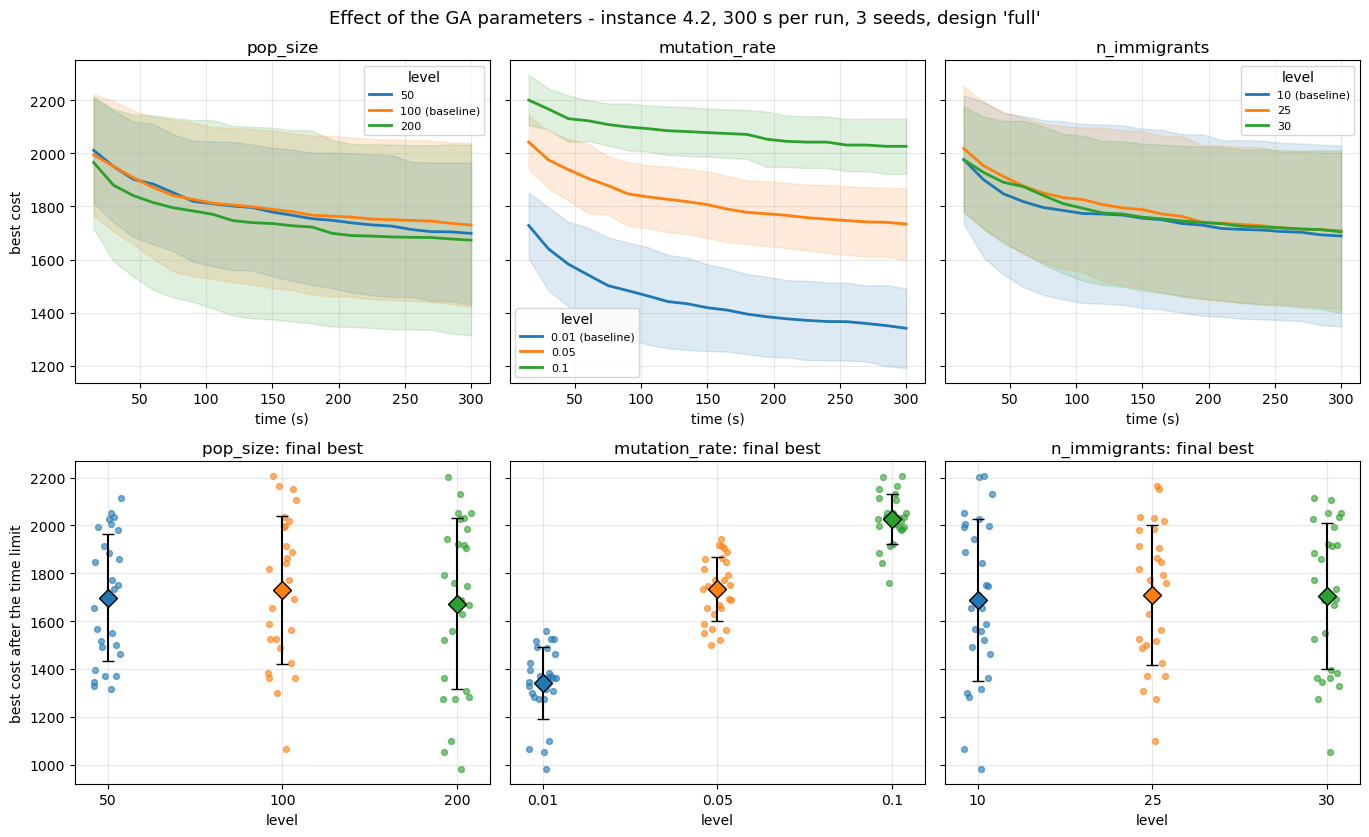

In [18]:
def rows_for(df, factor, level):
    """Runs that represent `level` of `factor`."""
    sel = df[factor] == level
    if DESIGN == "ofat":
        sel &= df["varied"].isin([factor, "baseline"])
    return df[sel]


Q_COLS = [f"best_q{q:02d}" for q in range(1, N_CHECKPOINTS + 1)]
T_GRID = TIME_LIMIT_S * np.arange(1, N_CHECKPOINTS + 1) / N_CHECKPOINTS

df = current_results()
if len(df):
    colors = plt.cm.tab10.colors
    fig, axes = plt.subplots(2, len(FACTORS), figsize=(4.6 * len(FACTORS), 8.5), squeeze=False, sharey="row")
    for k, (f, levels) in enumerate(FACTORS.items()):
        ax_t, ax_b = axes[0, k], axes[1, k]
        for li, lv in enumerate(levels):
            r = rows_for(df, f, lv)
            if r.empty:
                continue
            mean, std = r[Q_COLS].mean().values, r[Q_COLS].std().fillna(0).values
            tag = f"{lv}" + (" (baseline)" if lv == BASELINE[f] else "")
            ax_t.plot(T_GRID, mean, color=colors[li], lw=2, label=tag)
            ax_t.fill_between(T_GRID, mean - std, mean + std, color=colors[li], alpha=0.15)
            ax_b.scatter(np.full(len(r), li) + np.random.default_rng(0).uniform(-0.08, 0.08, len(r)), r["best"],
                         s=18, color=colors[li], alpha=0.6)
            ax_b.errorbar(li, r["best"].mean(), yerr=r["best"].std() if len(r) > 1 else 0, fmt="D", color="black",
                          mfc=colors[li], ms=9, capsize=4, zorder=3)
        ax_t.set(title=f, xlabel="time (s)", ylabel="best cost" if k == 0 else "")
        ax_t.legend(title="level", fontsize=8)
        ax_t.grid(alpha=0.3)
        ax_b.set_xticks(range(len(levels)))
        ax_b.set_xticklabels([str(v) for v in levels])
        ax_b.set(title=f"{f}: final best", xlabel="level", ylabel="best cost after the time limit" if k == 0 else "")
        ax_b.grid(alpha=0.3)
    fig.suptitle(f"Effect of the GA parameters - instance {EXP_LABEL}, {TIME_LIMIT_S} s per run, {len(SEEDS)} seeds, design '{DESIGN}'", fontsize=13)
    plt.tight_layout()
    fig.savefig("ga_experiment_effects.png", dpi=150)
    plt.show()


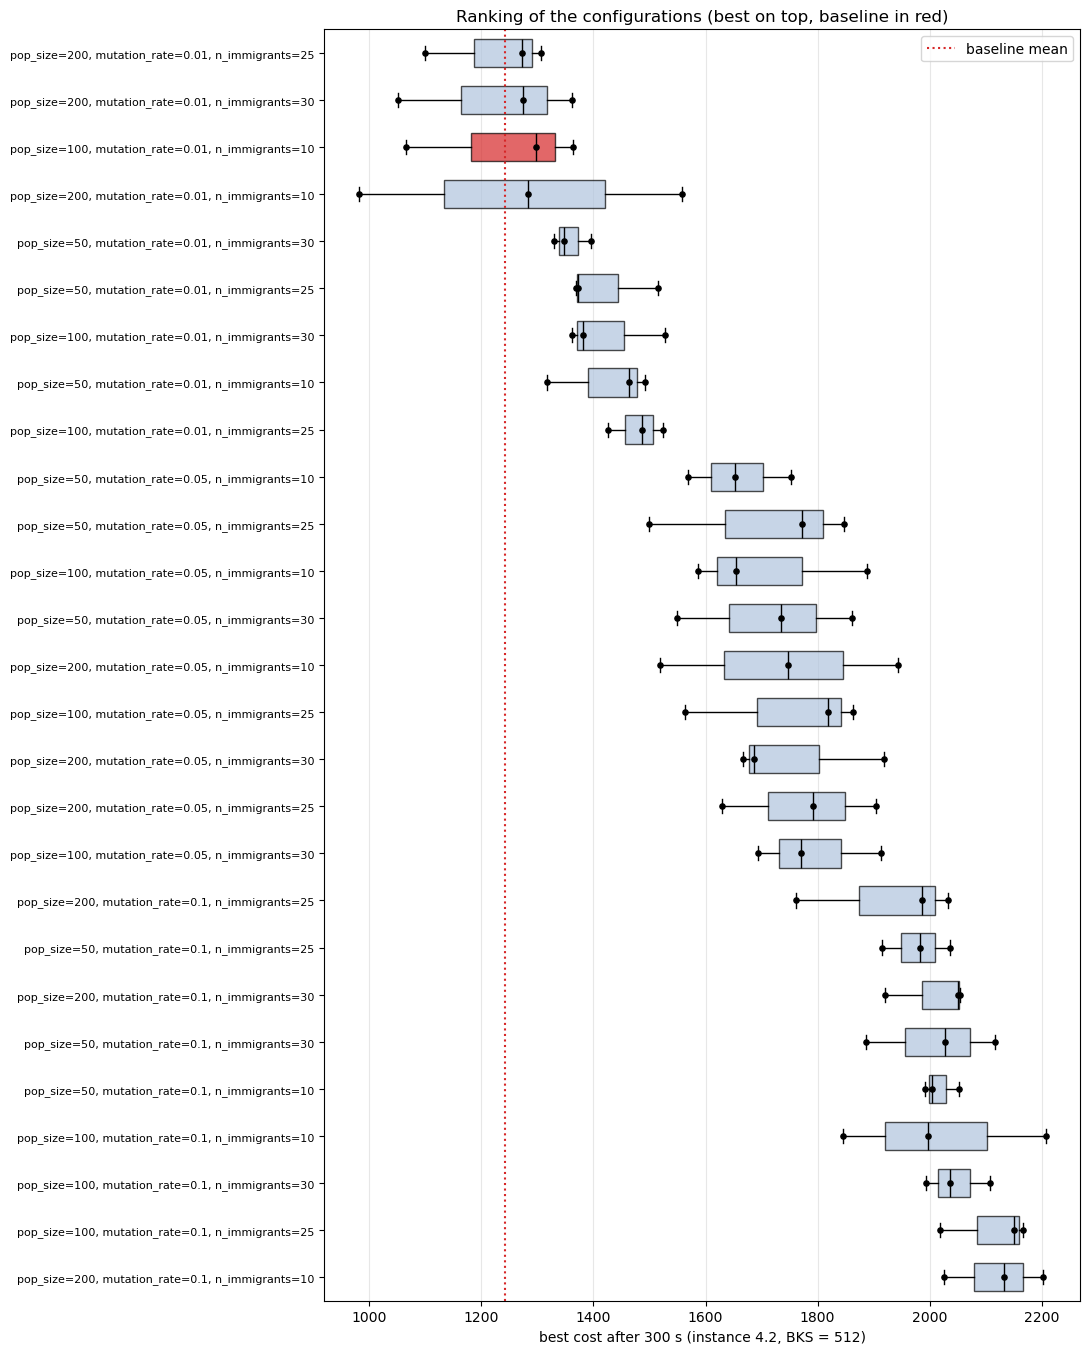

In [19]:
# ---- Figure 2: ranking of all the configurations ----------------------------------------------------------------
df = current_results()
if len(df):
    order = (df.groupby("config_id")["best"].mean().sort_values().index.tolist())
    shown = order if len(order) <= 30 else order[:25] + [c for c in order[25:] if c == base_id][:1]
    fig, ax = plt.subplots(figsize=(11, 0.45 * len(shown) + 1.5))
    data = [df.loc[df["config_id"] == c, "best"].values for c in shown]
    bp = ax.boxplot(data, vert=False, patch_artist=True, widths=0.6, medianprops={"color": "black"})
    for patch, c in zip(bp["boxes"], shown):
        patch.set_facecolor("tab:red" if c == base_id else "lightsteelblue")
        patch.set_alpha(0.7)
    for i, vals in enumerate(data, start=1):
        ax.scatter(vals, np.full(len(vals), i), s=14, color="black", zorder=3)
    ax.set_yticks(range(1, len(shown) + 1))
    ax.set_yticklabels(shown, fontsize=8)
    ax.invert_yaxis()
    ax.axvline(df.loc[df["config_id"] == base_id, "best"].mean(), color="tab:red", ls=":", label="baseline mean")
    ax.set(xlabel=f"best cost after {TIME_LIMIT_S} s (instance {EXP_LABEL}, BKS = {BKS[EXP_LABEL]})",
           title="Ranking of the configurations (best on top, baseline in red)")
    ax.legend(); ax.grid(alpha=0.3, axis="x")
    plt.tight_layout()
    fig.savefig("ga_experiment_ranking.png", dpi=150)
    plt.show()
